# Audio Preprocessing & Segmentation: Audio Preprocessing and Multi-Scale Window Slicing

This notebook preprocesses both the raw Philippine Eagle recordings and the sympatric hard-negatives corpus into standardized, fixed-duration snippets for model training and transfer learning:
1. **Philippine Eagle Dataset (`data/raw/eagle-audios/`)**:
   - Slices the 59 verified recordings into fixed windows at 22,050 Hz mono.
   - Discards any window overlapping with `Unnecessary` noise annotations.
   - Assigns binary labels (`is_eagle = True` / `label = 1` if call overlap >= 50%).
   - Labels non-call ambient intervals as `is_eagle = False` / `label = 0`.
2. **Hard Negatives Dataset (`data/raw/hard-negatives/`)**:
   - Loads multi-format recordings (`.wav`, `.mp3`, `.m4a`) across 9 sympatric raptor and forest species.
   - Applies sliding-window slicing with acoustic activity filtering (dropping pure digital silence).
   - Labels all extracted slices as `is_eagle = False` / `label = 0` with full species and provenance tracking.
3. **Multi-Scale Pipelines**:
   - **5.0-Second Preprocessing**: 5.0s window with 2.0s hop (primary target for custom CNN-GRU models).
   - **3.0-Second Preprocessing**: 3.0s window with 1.5s hop (compatible with BirdNET transfer learning).
4. **Caching Guards**:
   - Independent dataset-level and clip-level caching guards prevent redundant re-slicing and allow seamless resuming.
5. **Comparative Analysis & Visualizations**:
   - Saves comprehensive figures to `outputs/figures/preprocess-*.png`.


## 1. Imports and Configuration


In [1]:
import os
import re
import sys
import warnings
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
import scipy.ndimage
import audioread
from tqdm import tqdm

warnings.filterwarnings("ignore")

# Random seed
SEED = 42
np.random.seed(SEED)

NOTEBOOK_ID = "preprocess"

# Preprocessing parameters
TARGET_SR = 22050           # Resample to 22.05 kHz mono
WINDOW_SIZE_5S = 5.0        # 5.0-second window
HOP_SIZE_5S = 2.0           # 2.0-second hop (3.0s overlap)
WINDOW_SIZE_3S = 3.0        # 3.0-second window (standard for BirdNET)
HOP_SIZE_3S = 1.5           # 1.5-second hop (1.5s / 50% overlap)
CALL_OVERLAP_THRESH = 0.50  # Overlap threshold: >= 50% of call duration in window
MIN_RMS_THRESHOLD = 0.001   # Filter out dead air / pure silence in field recordings

# Directory paths
CURRENT_PATH = Path.cwd()
def find_project_root():
    p = Path.cwd().resolve()
    while p != p.parent:
        if (p / "data").exists() and (p / "AGENTS.md").exists():
            return p
        p = p.parent
    return Path.cwd().resolve().parent.parent

PROJECT_ROOT = find_project_root()
EXPERIMENT_DIR = Path.cwd().resolve()
OUTPUTS_DIR = EXPERIMENT_DIR / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"


DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"

# Eagle audios directory paths
EAGLE_RAW_DIR = RAW_DIR / "eagle-audios"
AUDIO_DIR = EAGLE_RAW_DIR / "audios"
TABLES_DIR = EAGLE_RAW_DIR / "selectionTables"
EAGLE_META_PATH = EAGLE_RAW_DIR / "raw-metadata.csv"

# Hard negatives directory paths
HARD_NEG_RAW_DIR = RAW_DIR / "hard-negatives"
HARD_NEG_AUDIO_DIR = HARD_NEG_RAW_DIR / "audios"
HARD_NEG_META_PATH = HARD_NEG_RAW_DIR / "raw-metadata.csv"

PREPROCESSED_DIR = DATA_DIR / "preprocessed"

# 5-second directory paths
DIR_5S = PREPROCESSED_DIR / "5-seconds"
OUTPUT_AUDIO_5S = DIR_5S / "audios"
METADATA_5S_PATH = DIR_5S / "metadata.csv"

# 3-second directory paths
DIR_3S = PREPROCESSED_DIR / "3-seconds"
OUTPUT_AUDIO_3S = DIR_3S / "audios"
METADATA_3S_PATH = DIR_3S / "metadata.csv"




# Ensure output directories exist
OUTPUT_AUDIO_5S.mkdir(parents=True, exist_ok=True)
OUTPUT_AUDIO_3S.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 150

print(f"Project root:               {PROJECT_ROOT}")
print(f"Eagle audio dir:            {AUDIO_DIR}")
print(f"Eagle selection tables dir: {TABLES_DIR}")
print(f"Hard negatives audio dir:   {HARD_NEG_AUDIO_DIR}")
print(f"5-second audio dir:         {OUTPUT_AUDIO_5S}")
print(f"3-second audio dir:         {OUTPUT_AUDIO_3S}")
print(f"Figures output dir:         {FIGURES_DIR}")
print(f"Target sample rate:         {TARGET_SR} Hz")
print(f"5s Window / Hop:            {WINDOW_SIZE_5S}s / {HOP_SIZE_5S}s")
print(f"3s Window / Hop:            {WINDOW_SIZE_3S}s / {HOP_SIZE_3S}s")
print(f"Call overlap thresh:        {CALL_OVERLAP_THRESH * 100:.0f}%")


Project root:               /home/fumei/Documents/MachineLearning/EagleSoundClassification
Eagle audio dir:            /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/raw/eagle-audios/audios
Eagle selection tables dir: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/raw/eagle-audios/selectionTables
Hard negatives audio dir:   /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/raw/hard-negatives/audios
5-second audio dir:         /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/5-seconds/audios
3-second audio dir:         /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/3-seconds/audios
Figures output dir:         /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/preprocess/outputs/figures
Target sample rate:         22050 Hz
5s Window / Hop:            5.0s / 2.0s
3s Window / Hop:            3.0s / 1.5s
Call overlap thresh:        50%


## 2. Load Raw Metadata and Catalog Lookups


In [2]:
# Load raw metadata and build lookup for site and age/sex
df_eagle_meta = pd.read_csv(EAGLE_META_PATH)
df_eagle_meta["ML Catalog Number"] = df_eagle_meta["ML Catalog Number"].astype(str).str.strip()
eagle_meta_lookup = df_eagle_meta.set_index("ML Catalog Number").to_dict("index")

# Load Hard Negatives catalog metadata (skipping 3 merge-csv comment lines)
df_hard_neg_meta_raw = pd.read_csv(HARD_NEG_META_PATH, skiprows=3)
col0 = df_hard_neg_meta_raw.columns[0]
df_hard_neg_meta = df_hard_neg_meta_raw.rename(columns={col0: "catalog_number"}).copy()
df_hard_neg_meta["catalog_number"] = df_hard_neg_meta["catalog_number"].astype(str).str.strip()

hard_neg_lookup = {}
for _, row in df_hard_neg_meta.iterrows():
    cat = row["catalog_number"]
    hard_neg_lookup[cat] = {
        "species": row.get("Common Name", "Unknown Avian"),
        "scientific_name": row.get("Scientific Name", "none"),
        "site": row.get("State", "Unknown") if pd.notna(row.get("State")) else "Unknown",
        "age_sex": row.get("Age/Sex", "Unknown") if pd.notna(row.get("Age/Sex")) else "Unknown"
    }

print(f"Loaded raw metadata: {len(df_eagle_meta)} eagle catalog entries.")
print(f"Loaded {len(hard_neg_lookup)} hard-negative catalog records spanning {df_hard_neg_meta['Common Name'].nunique()} species.")

# Scan audio files and selection tables
eagle_audio_files = sorted(list(AUDIO_DIR.glob("*.wav")))
eagle_table_files = sorted(list(TABLES_DIR.glob("*.txt")))

eagle_audio_dict = {f.stem: f for f in eagle_audio_files}
eagle_table_dict = {f.stem: f for f in eagle_table_files}
valid_eagle_stems = sorted(list(set(eagle_audio_dict.keys()) & set(eagle_table_dict.keys())))

# Scan hard-negatives audio files (.wav, .mp3, .m4a)
hard_neg_files = sorted([
    f for f in HARD_NEG_AUDIO_DIR.iterdir()
    if f.suffix.lower() in [".wav", ".mp3", ".m4a"]
])

print("=" * 60)
print(f"Valid paired Eagle recordings to preprocess: {len(valid_eagle_stems)}")
print(f"Valid Hard Negative audio files to process:  {len(hard_neg_files)}")
print("=" * 60)


Loaded raw metadata: 60 eagle catalog entries.
Loaded 707 hard-negative catalog records spanning 9 species.
Valid paired Eagle recordings to preprocess: 59
Valid Hard Negative audio files to process:  707


## 3. Helper Functions for Audio Loading, Annotation Parsing, and Slicing


In [3]:
def extract_catalog_number(stem: str) -> str:
    """Extract numeric catalog digits from filename stem."""
    match = re.search(r"\d+", stem)
    return match.group(0) if match else ""


def load_audio_unified(file_path: Path, target_sr: int = 22050):
    """
    Load audio across .wav, .mp3, and AAC-encoded .m4a files converted to mono float32 at target_sr.
    """
    try:
        y, sr = librosa.load(file_path, sr=target_sr, mono=True)
        return y, sr
    except Exception:
        # Fallback for .m4a / AAC containers using audioread
        with audioread.audio_open(str(file_path)) as a:
            raw_data = [buf for buf in a]
            raw_bytes = b"".join(raw_data)
            audio = np.frombuffer(raw_bytes, dtype=np.int16).astype(np.float32) / 32768.0
            if a.channels > 1:
                audio = audio.reshape(-1, a.channels).mean(axis=1)
            orig_sr = a.samplerate
            if orig_sr != target_sr:
                audio = librosa.resample(audio, orig_sr=orig_sr, target_sr=target_sr)
            return audio, target_sr


def parse_selection_table(table_path: Path):
    """Parse selection table into eagle calls, unnecessary noise intervals, and ambiguous intervals."""
    df = pd.read_csv(table_path, sep="\t")
    df.columns = [c.strip() for c in df.columns]

    eagle_calls = []
    unnecessary = []
    ambiguous = []

    for _, row in df.iterrows():
        b = float(row["Begin Time (s)"])
        e = float(row["End Time (s)"])
        sel_id = int(row["Selection"])
        raw_type = str(row["Type"]).strip()

        # Check for unnecessary noise variations
        if re.search(r"un+ec+es+", raw_type, re.IGNORECASE):
            unnecessary.append((b, e))
        elif re.search(r"ambiguous", raw_type, re.IGNORECASE):
            ambiguous.append((b, e))
        elif re.search(r"PhilEagle", raw_type, re.IGNORECASE):
            c_type = "PhilEagle_long" if "long" in raw_type.lower() else "PhilEagle_short"
            eagle_calls.append({
                "selection_id": sel_id,
                "call_type": c_type,
                "begin": b,
                "end": e,
                "duration": max(0.0, e - b)
            })

    return eagle_calls, unnecessary, ambiguous


def compute_interval_overlap(start1: float, end1: float, start2: float, end2: float) -> float:
    """Calculate temporal overlap duration between two time intervals [start1, end1] and [start2, end2]."""
    return max(0.0, min(end1, end2) - max(start1, start2))


def slice_eagle_dataset(
    stems,
    audio_map,
    table_map,
    meta_lookup_dict,
    window_size: float,
    hop_size: float,
    target_sr: int,
    call_overlap_thresh: float,
    output_audio_dir: Path,
    relative_dir_name: str
):
    """
    Slices raw Philippine Eagle recordings into fixed-duration windows, applying noise filtering and labels.
    """
    metadata_records = []
    win_samples = int(window_size * target_sr)
    hop_samples = int(hop_size * target_sr)

    print(f"Starting Eagle window slicing ({window_size}s window, {hop_size}s hop) for {len(stems)} recordings...")

    for stem in tqdm(stems, desc=f"Slicing Eagle {window_size}s Clips"):
        audio_path = audio_map[stem]
        table_path = table_map[stem]

        cat_num = extract_catalog_number(stem)
        rec_meta = meta_lookup_dict.get(cat_num, {})
        site = rec_meta.get("State", "Unknown")
        age_sex = rec_meta.get("Age/Sex", "Unknown")

        eagle_calls, unnecessary_intervals, ambiguous_intervals = parse_selection_table(table_path)
        y, sr = load_audio_unified(audio_path, target_sr=target_sr)
        total_audio_samples = len(y)

        if total_audio_samples < win_samples:
            window_ranges = [(0, total_audio_samples)]
        else:
            window_ranges = [
                (start_idx, start_idx + win_samples)
                for start_idx in range(0, total_audio_samples - win_samples + 1, hop_samples)
            ]

        for start_idx, end_idx in window_ranges:
            w_start = start_idx / target_sr
            w_end = end_idx / target_sr
            slice_duration = round(w_end - w_start, 2)

            is_unnecessary = any(
                compute_interval_overlap(w_start, w_end, u_b, u_e) > 0.001
                for u_b, u_e in unnecessary_intervals
            )
            if is_unnecessary:
                continue

            matching_calls = []
            for call in eagle_calls:
                if call["duration"] <= 0:
                    continue
                overlap_sec = compute_interval_overlap(w_start, w_end, call["begin"], call["end"])
                overlap_ratio = overlap_sec / call["duration"]
                if overlap_ratio >= call_overlap_thresh:
                    matching_calls.append({
                        "selection_id": call["selection_id"],
                        "call_type": call["call_type"],
                        "overlap_sec": overlap_sec,
                        "overlap_ratio": overlap_ratio
                    })

            has_ambiguous = any(
                compute_interval_overlap(w_start, w_end, a_b, a_e) > 0.001
                for a_b, a_e in ambiguous_intervals
            )

            if len(matching_calls) > 0:
                is_eagle = True
                label = 1
                call_types = ";".join(sorted(list({c["call_type"] for c in matching_calls})))
                call_ids = ";".join([str(c["selection_id"]) for c in matching_calls])
                call_uid = ";".join([f"{stem}_call_{c['selection_id']}" for c in matching_calls])
                call_overlap_ratio = round(max(c["overlap_ratio"] for c in matching_calls), 4)
                species = "Philippine Eagle"
                scientific_name = "Pithecophaga jefferyi"
            else:
                is_eagle = False
                label = 0
                call_types = "none"
                call_ids = "none"
                call_uid = "none"
                call_overlap_ratio = 0.0
                species = "Philippine Eagle Territory (Ambient)"
                scientific_name = "none"

            slice_filename = f"{stem}_{w_start:07.1f}_{w_end:07.1f}.wav"
            slice_filepath = output_audio_dir / slice_filename

            if not slice_filepath.exists():
                audio_slice = y[start_idx:end_idx]
                sf.write(slice_filepath, audio_slice, target_sr, subtype="PCM_16")

            relative_filepath = f"{relative_dir_name}/{slice_filename}"
            metadata_records.append({
                "file_name": slice_filename,
                "file_path": relative_filepath,
                "source_audio": audio_path.name,
                "site": site,
                "age_sex": age_sex,
                "start_time": round(w_start, 2),
                "end_time": round(w_end, 2),
                "duration": slice_duration,
                "sample_rate": target_sr,
                "is_eagle": is_eagle,
                "label": label,
                "call_types": call_types,
                "call_ids": call_ids,
                "call_uid": call_uid,
                "call_overlap_ratio": call_overlap_ratio,
                "has_ambiguous": has_ambiguous,
                "species": species,
                "scientific_name": scientific_name,
                "dataset_source": "eagle-audios"
            })

    return metadata_records


def detect_acoustic_call_intervals(
    y: np.ndarray,
    sr: int,
    snr_factor: float = 2.0,
    min_call_dur: float = 0.15,
    min_peak_rms: float = 0.008
):
    """
    Detects bird vocalization intervals [begin, end, duration] in unannotated audio
    using adaptive energy thresholding against the recording's baseline noise floor.
    """
    frame_len = int(0.1 * sr)   # 100ms window
    hop_len = int(0.05 * sr)   # 50ms hop
    rms = librosa.feature.rms(y=y, frame_length=frame_len, hop_length=hop_len)[0]
    times = librosa.times_like(rms, sr=sr, hop_length=hop_len)

    median_rms = float(np.median(rms))
    std_rms = float(np.std(rms))
    thresh = max(median_rms + snr_factor * std_rms, min_peak_rms)

    is_active = rms >= thresh
    if not np.any(is_active):
        max_idx = np.argmax(rms)
        if rms[max_idx] >= (min_peak_rms * 0.6):
            t_peak = times[max_idx]
            return [{"begin": max(0.0, t_peak - 0.5), "end": min(len(y)/sr, t_peak + 0.5), "duration": 1.0}]
        return []

    labeled, num_events = scipy.ndimage.label(is_active)
    call_intervals = []
    for feat_id in range(1, num_events + 1):
        idx = np.where(labeled == feat_id)[0]
        start_t = times[idx[0]]
        end_t = times[idx[-1]] + (hop_len / sr)
        dur = end_t - start_t
        if dur >= min_call_dur:
            call_intervals.append({
                "begin": round(start_t, 2),
                "end": round(end_t, 2),
                "duration": dur
            })

    return call_intervals


def slice_hard_negatives_dataset(
    audio_files,
    hard_neg_lookup_dict,
    window_size: float,
    hop_size: float,
    target_sr: int,
    call_overlap_thresh: float,
    output_audio_dir: Path,
    relative_dir_name: str
):
    """
    Slices raw hard-negative recordings using a natural sliding window,
    retaining only windows that capture at least call_overlap_thresh (>= 50%)
    of an active bird vocalization duration (identical standard to Eagle calls).
    """
    metadata_records = []
    win_samples = int(window_size * target_sr)
    hop_samples = int(hop_size * target_sr)

    print(f"Starting Call-Active Hard Negatives slicing ({window_size}s window, {hop_size}s hop, >= {int(call_overlap_thresh * 100)}% call overlap) for {len(audio_files)} recordings...")

    for audio_path in tqdm(audio_files, desc=f"Slicing Hard Negatives {window_size}s"):
        stem = audio_path.stem.strip()
        cat_info = hard_neg_lookup_dict.get(stem, {})

        species = cat_info.get("species", "Unknown Avian")
        scientific_name = cat_info.get("scientific_name", "none")
        site = cat_info.get("site", "Unknown")
        age_sex = cat_info.get("age_sex", "Unknown")

        try:
            y, sr = load_audio_unified(audio_path, target_sr=target_sr)
        except Exception as e:
            print(f"Error loading {audio_path.name}: {e}")
            continue

        if len(y) < 100:
            continue

        # 1. Detect all bird vocalization intervals in this recording
        detected_calls = detect_acoustic_call_intervals(y, target_sr)
        if not detected_calls:
            continue

        # 2. Sliding window ranges across the recording
        total_audio_samples = len(y)
        if total_audio_samples < win_samples:
            window_ranges = [(0, total_audio_samples)]
        else:
            window_ranges = [
                (start_idx, start_idx + win_samples)
                for start_idx in range(0, total_audio_samples - win_samples + 1, hop_samples)
            ]

        for start_idx, end_idx in window_ranges:
            w_start = start_idx / target_sr
            w_end = (start_idx + win_samples) / target_sr
            slice_duration = round(window_size, 2)

            # 3. Check overlap with detected bird calls (identical rule to eagle preprocessing)
            matching_calls = []
            for call in detected_calls:
                if call["duration"] <= 0:
                    continue
                overlap_sec = compute_interval_overlap(w_start, w_end, call["begin"], call["end"])
                overlap_ratio = overlap_sec / call["duration"]
                if overlap_ratio >= call_overlap_thresh:
                    matching_calls.append(overlap_ratio)

            # Keep slice ONLY if at least 50% of a call duration is inside this window
            if len(matching_calls) > 0:
                audio_slice = y[start_idx:end_idx]
                if len(audio_slice) < win_samples:
                    audio_slice = np.pad(audio_slice, (0, win_samples - len(audio_slice)), mode="constant")

                slice_filename = f"hardneg_{stem}_{w_start:07.1f}_{w_end:07.1f}.wav"
                slice_filepath = output_audio_dir / slice_filename

                if not slice_filepath.exists():
                    sf.write(slice_filepath, audio_slice, target_sr, subtype="PCM_16")

                relative_filepath = f"{relative_dir_name}/{slice_filename}"
                metadata_records.append({
                    "file_name": slice_filename,
                    "file_path": relative_filepath,
                    "source_audio": audio_path.name,
                    "site": site,
                    "age_sex": age_sex,
                    "start_time": round(w_start, 2),
                    "end_time": round(w_end, 2),
                    "duration": slice_duration,
                    "sample_rate": target_sr,
                    "is_eagle": False,
                    "label": 0,
                    "call_types": "none",
                    "call_ids": "none",
                    "call_uid": "none",
                    "call_overlap_ratio": round(max(matching_calls), 4),
                    "has_ambiguous": False,
                    "species": species,
                    "scientific_name": scientific_name,
                    "dataset_source": "hard-negatives"
                })

    return metadata_records


### 3.1. Window Distribution Plotting Helper

In [4]:
def plot_window_distributions(df_metadata, scale_tag, window_label):
    """
    Save four figures for one window length: windows per binary class, windows per category,
    eagle-recording windows per site, and hard-negative windows per species. Windows flagged as ambiguous are left out, since they are not used for modelling.
    """
    df_kept = df_metadata[~df_metadata["has_ambiguous"].fillna(False).astype(bool)].copy()
    n_removed = len(df_metadata) - len(df_kept)
    df_kept["group"] = np.where(
        df_kept["label"] == 1, "Eagle call",
        np.where(df_kept["dataset_source"] == "hard-negatives", "Hard negative", "Ambient")
    )
    colors = {"Eagle call": "#2e7d32", "Ambient": "#2874a6", "Hard negative": "#e65100"}

    def save(fig, name):
        path = FIGURES_DIR / f"{scale_tag}-{name}.png"
        fig.savefig(path, dpi=300, bbox_inches="tight")
        print(f"Saved figure: {path}")
        plt.show()

    group_counts = df_kept["group"].value_counts().reindex(["Eagle call", "Ambient", "Hard negative"], fill_value=0)

    # 1. Windows per binary class; the negative bar is split into its ambient and hard-negative parts
    n_eagle, n_ambient, n_hard = (int(group_counts[g]) for g in ["Eagle call", "Ambient", "Hard negative"])
    n_negative = n_ambient + n_hard
    class_names = ["Eagle Call (1)", "No Eagle Call (0)"]
    fig, ax = plt.subplots(figsize=(6.5, 4.8))
    ax.bar(class_names[0], n_eagle, color=colors["Eagle call"], edgecolor="black", width=0.55, label="Eagle call")
    ax.bar(class_names[1], n_ambient, color=colors["Ambient"], edgecolor="black", width=0.55, label="Ambient")
    ax.bar(class_names[1], n_hard, bottom=n_ambient, color=colors["Hard negative"], edgecolor="black", width=0.55, label="Hard negative")
    for x_pos, count in enumerate([n_eagle, n_negative]):
        ax.annotate(f"{count:,}\n({count / len(df_kept) * 100:.1f}%)", (x_pos, count),
                    xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.annotate(f"Ambient\n{n_ambient:,}", (1, n_ambient / 2), ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    ax.annotate(f"Hard negative\n{n_hard:,}", (1, n_ambient + n_hard / 2), ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    ax.set_ylim(0, max(n_eagle, n_negative) * 1.18)
    ax.set_ylabel("Number of windows")
    ax.set_title(f"Windows per Class after Preprocessing ({window_label}, {len(df_kept):,} windows)", fontweight="bold")
    ax.legend(frameon=True, loc="upper left")
    plt.tight_layout()
    save(fig, "class-distribution")

    # 2. Windows per category
    fig, ax = plt.subplots(figsize=(7, 4.8))
    bars = ax.bar(group_counts.index, group_counts.values, color=[colors[g] for g in group_counts.index], edgecolor="black", width=0.6)
    for bar, count in zip(bars, group_counts.values):
        ax.annotate(f"{count:,}\n({count / len(df_kept) * 100:.1f}%)", (bar.get_x() + bar.get_width() / 2, count),
                    xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_ylim(0, group_counts.max() * 1.18)
    ax.set_ylabel("Number of windows")
    ax.set_title(f"Windows per Category after Preprocessing ({window_label}, {len(df_kept):,} windows)", fontweight="bold")
    plt.tight_layout()
    save(fig, "window-category-distribution")

    # 3. Windows from the eagle recordings per site
    df_eagle = df_kept[df_kept["dataset_source"] == "eagle-audios"]
    site_counts = pd.crosstab(df_eagle["site"], df_eagle["group"]).reindex(columns=["Eagle call", "Ambient"], fill_value=0)
    site_counts = site_counts.sort_values("Eagle call", ascending=False)
    fig, ax = plt.subplots(figsize=(10, 4.8))
    x = np.arange(len(site_counts))
    width = 0.38
    for offset, name in [(-width / 2, "Eagle call"), (width / 2, "Ambient")]:
        bars = ax.bar(x + offset, site_counts[name].values, width, label=name, color=colors[name], edgecolor="black")
        for bar, count in zip(bars, site_counts[name].values):
            ax.annotate(f"{count:,}", (bar.get_x() + bar.get_width() / 2, count),
                        xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(site_counts.index)
    ax.set_ylim(0, site_counts.values.max() * 1.12)
    ax.set_ylabel("Number of windows")
    ax.set_title(f"Windows from Philippine Eagle Recordings per Site ({window_label})", fontweight="bold")
    ax.legend(frameon=True)
    plt.tight_layout()
    save(fig, "eagle-site-distribution")

    # 4. Hard-negative windows per species
    species_counts = df_kept[df_kept["group"] == "Hard negative"]["species"].value_counts().sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.barh(species_counts.index, species_counts.values, color=colors["Hard negative"], edgecolor="black", height=0.65)
    for bar, count in zip(bars, species_counts.values):
        ax.annotate(f"{count:,} ({count / species_counts.sum() * 100:.1f}%)", (count, bar.get_y() + bar.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points", ha="left", va="center", fontsize=9, fontweight="bold")
    ax.set_xlim(0, species_counts.max() * 1.22)
    ax.set_xlabel("Number of windows")
    ax.set_title(f"Hard-Negative Windows per Species ({window_label}, {species_counts.sum():,} windows)", fontweight="bold")
    plt.tight_layout()
    save(fig, "hard-negative-species-distribution")

    print(f"Windows shown: {len(df_kept):,} ({n_removed} ambiguous windows left out)")
    display(group_counts.rename("windows").to_frame())
    display(site_counts)


### 3.2. Hard-Negative Recording Exclusion Diagnosis Helper

In [5]:
def diagnose_hard_negative_recordings(
    audio_files,
    hard_neg_lookup_dict,
    window_settings,
    target_sr: int,
    call_overlap_thresh: float
):
    """
    Follows the steps of slice_hard_negatives_dataset for every raw hard-negative recording
    and records where it stops, without writing any audio.
    window_settings is a list of (tag, window_size, hop_size), for example ("3s", 3.0, 1.5).
    Returns one row per recording with the outcome and the number of kept windows per setting.
    """
    rows = []

    for audio_path in tqdm(audio_files, desc="Checking Hard Negative recordings"):
        stem = audio_path.stem.strip()
        row = {
            "source_audio": audio_path.name,
            "species": hard_neg_lookup_dict.get(stem, {}).get("species", "Unknown Avian"),
            "format": audio_path.suffix.lower(),
            "duration_sec": np.nan,
            "detected_events": 0,
            "load_error": "",
        }

        early_outcome = None
        try:
            y, sr = load_audio_unified(audio_path, target_sr=target_sr)
        except Exception as e:
            early_outcome = "Could not be loaded"
            row["load_error"] = str(e)[:120]

        if early_outcome is None:
            row["duration_sec"] = round(len(y) / target_sr, 2)
            if len(y) < 100:
                early_outcome = "Too short (under 100 samples)"

        if early_outcome is None:
            detected_calls = detect_acoustic_call_intervals(y, target_sr)
            row["detected_events"] = len(detected_calls)
            if not detected_calls:
                early_outcome = "No vocalization found by the energy filter"

        for tag, window_size, hop_size in window_settings:
            if early_outcome is not None:
                row[f"outcome_{tag}"] = early_outcome
                row[f"windows_{tag}"] = 0
                continue

            win_samples = int(window_size * target_sr)
            hop_samples = int(hop_size * target_sr)
            total_audio_samples = len(y)
            if total_audio_samples < win_samples:
                window_starts = [0]
            else:
                window_starts = range(0, total_audio_samples - win_samples + 1, hop_samples)

            kept_windows = 0
            for start_idx in window_starts:
                w_start = start_idx / target_sr
                w_end = (start_idx + win_samples) / target_sr
                for call in detected_calls:
                    if call["duration"] <= 0:
                        continue
                    overlap_sec = compute_interval_overlap(w_start, w_end, call["begin"], call["end"])
                    if overlap_sec / call["duration"] >= call_overlap_thresh:
                        kept_windows += 1
                        break

            row[f"windows_{tag}"] = kept_windows
            row[f"outcome_{tag}"] = (
                "Kept (at least one window)" if kept_windows > 0
                else f"Vocalization found, but no window holds at least {int(call_overlap_thresh * 100)}% of one"
            )

        rows.append(row)

    return pd.DataFrame(rows)

## 4. Preprocessing: 5.0-Second Windows


### 4.1. Slice 5.0-Second Philippine Eagle Recordings


In [6]:
# Caching guard for eagle 5s slices
existing_eagle_5s = list(OUTPUT_AUDIO_5S.glob("converted_*.wav"))

if len(existing_eagle_5s) > 0 and METADATA_5S_PATH.exists():
    print(f"Caching Guard: Found {len(existing_eagle_5s)} cached Eagle 5.0s slices. Loading existing metadata records...")
    df_existing_5s = pd.read_csv(METADATA_5S_PATH)
    if "dataset_source" in df_existing_5s.columns:
        records_eagle_5s = df_existing_5s[df_existing_5s["dataset_source"] == "eagle-audios"].to_dict("records")
    else:
        # Backward compatibility: all legacy entries were eagle audios
        records_eagle_5s = df_existing_5s.to_dict("records")
        for r in records_eagle_5s:
            r["dataset_source"] = "eagle-audios"
            r["species"] = "Philippine Eagle" if r.get("is_eagle") else "Philippine Eagle Territory (Ambient)"
            r["scientific_name"] = "Pithecophaga jefferyi" if r.get("is_eagle") else "none"
else:
    records_eagle_5s = slice_eagle_dataset(
        stems=valid_eagle_stems,
        audio_map=eagle_audio_dict,
        table_map=eagle_table_dict,
        meta_lookup_dict=eagle_meta_lookup,
        window_size=WINDOW_SIZE_5S,
        hop_size=HOP_SIZE_5S,
        target_sr=TARGET_SR,
        call_overlap_thresh=CALL_OVERLAP_THRESH,
        output_audio_dir=OUTPUT_AUDIO_5S,
        relative_dir_name="data/preprocessed/5-seconds/audios"
    )

print(f"Total valid Eagle 5.0s slices: {len(records_eagle_5s)}")


Caching Guard: Found 6511 cached Eagle 5.0s slices. Loading existing metadata records...
Total valid Eagle 5.0s slices: 6511


### 4.2. Slice 5.0-Second Hard Negatives with Activity Filtering


In [7]:
# Caching guard for hard negatives 5s slices
existing_hardneg_5s = list(OUTPUT_AUDIO_5S.glob("hardneg_*.wav"))

if len(existing_hardneg_5s) > 0 and METADATA_5S_PATH.exists():
    df_existing_5s = pd.read_csv(METADATA_5S_PATH)
    if "dataset_source" in df_existing_5s.columns and (df_existing_5s["dataset_source"] == "hard-negatives").sum() > 0:
        print(f"Caching Guard: Found {len(existing_hardneg_5s)} cached Hard Negative 5.0s slices. Loading records...")
        records_hardneg_5s = df_existing_5s[df_existing_5s["dataset_source"] == "hard-negatives"].to_dict("records")
    else:
        records_hardneg_5s = slice_hard_negatives_dataset(
            audio_files=hard_neg_files,
            hard_neg_lookup_dict=hard_neg_lookup,
            window_size=WINDOW_SIZE_5S,
            hop_size=HOP_SIZE_5S,
            target_sr=TARGET_SR,
            call_overlap_thresh=CALL_OVERLAP_THRESH,
            output_audio_dir=OUTPUT_AUDIO_5S,
            relative_dir_name="data/preprocessed/5-seconds/audios"
        )
else:
    records_hardneg_5s = slice_hard_negatives_dataset(
        audio_files=hard_neg_files,
        hard_neg_lookup_dict=hard_neg_lookup,
        window_size=WINDOW_SIZE_5S,
        hop_size=HOP_SIZE_5S,
        target_sr=TARGET_SR,
        call_overlap_thresh=CALL_OVERLAP_THRESH,
        output_audio_dir=OUTPUT_AUDIO_5S,
        relative_dir_name="data/preprocessed/5-seconds/audios"
    )

print(f"Total valid Hard Negatives 5.0s slices: {len(records_hardneg_5s)}")

Caching Guard: Found 2539 cached Hard Negative 5.0s slices. Loading records...
Total valid Hard Negatives 5.0s slices: 2539


### 4.3. Consolidate and Save 5.0-Second Preprocessed Metadata


In [8]:
# Consolidate Eagle and Hard Negative records into unified DataFrame
df_metadata_5s = pd.DataFrame(records_eagle_5s + records_hardneg_5s)

# Save to metadata CSV
df_metadata_5s.to_csv(METADATA_5S_PATH, index=False)
print(f"Successfully saved 5.0s metadata to: {METADATA_5S_PATH}")
print(f"Total 5.0s slices: {len(df_metadata_5s)}")
display(df_metadata_5s.head(5))


Successfully saved 5.0s metadata to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/5-seconds/metadata.csv
Total 5.0s slices: 9050


,file_name,file_path,source_audio,site,age_sex,start_time,end_time,duration,sample_rate,is_eagle,label,call_types,call_ids,call_uid,call_overlap_ratio,has_ambiguous,species,scientific_name,dataset_source
0,converted_135598_00006.0_00011.0.wav,data/preprocessed/5-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,6.0,11.0,5.0,22050,True,1,PhilEagle_long,2;3,converted_135598_call_2;converted_135598_call_3,1.0,False,Philippine Eagle,Pithecophaga jefferyi,eagle-audios
1,converted_135598_00008.0_00013.0.wav,data/preprocessed/5-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,8.0,13.0,5.0,22050,True,1,PhilEagle_long,3;4,converted_135598_call_3;converted_135598_call_4,1.0,False,Philippine Eagle,Pithecophaga jefferyi,eagle-audios
2,converted_135598_00010.0_00015.0.wav,data/preprocessed/5-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,10.0,15.0,5.0,22050,True,1,PhilEagle_long,4;5,converted_135598_call_4;converted_135598_call_5,1.0,False,Philippine Eagle,Pithecophaga jefferyi,eagle-audios
3,converted_135598_00012.0_00017.0.wav,data/preprocessed/5-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,12.0,17.0,5.0,22050,True,1,PhilEagle_long,5;6;7,converted_135598_call_5;converted_135598_call_...,1.0,False,Philippine Eagle,Pithecophaga jefferyi,eagle-audios
4,converted_135598_00014.0_00019.0.wav,data/preprocessed/5-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,14.0,19.0,5.0,22050,True,1,PhilEagle_long,6;7;8,converted_135598_call_6;converted_135598_call_...,1.0,False,Philippine Eagle,Pithecophaga jefferyi,eagle-audios


### 4.4. Analyze 5.0-Second Class, Species, and Site Distributions


In [9]:
# Analyze class balance, 3-way categories, and format distribution for 5.0s dataset
def get_slice_category(row):
    if row["label"] == 1:
        return "Philippine Eagle Call"
    elif row["dataset_source"] == "hard-negatives":
        return "Hard Negative"
    else:
        return "Normal Negative (Eagle Ambient)"

df_metadata_5s["category"] = df_metadata_5s.apply(get_slice_category, axis=1)
df_metadata_5s["source_format"] = df_metadata_5s["source_audio"].apply(lambda s: Path(str(s)).suffix.lower())

print("=" * 65)
print("5.0-SECOND DATASET SUMMARY & DISTRIBUTIONS")
print("=" * 65)
print(f"Total Preprocessed Slices: {len(df_metadata_5s)}")
print("\n1. Binary Labels (label):")
print(df_metadata_5s["label"].value_counts().rename({1: "Eagle Call (1)", 0: "No Eagle (0)"}))
print("\n2. Three-Way Category Distribution:")
print(df_metadata_5s["category"].value_counts())
print("\n3. Source Audio File Format Distribution:")
print(df_metadata_5s["source_format"].value_counts())
print(f"Output Slice Format: 100% .wav (PCM_16 @ {TARGET_SR} Hz)")
print("\n4. Top Species Breakdown:")
print(df_metadata_5s["species"].value_counts().head(10))
print("=" * 65)


5.0-SECOND DATASET SUMMARY & DISTRIBUTIONS
Total Preprocessed Slices: 9050

1. Binary Labels (label):
label
No Eagle (0)      6087
Eagle Call (1)    2963
Name: count, dtype: int64

2. Three-Way Category Distribution:
category
Normal Negative (Eagle Ambient)    3548
Philippine Eagle Call              2963
Hard Negative                      2539
Name: count, dtype: int64

3. Source Audio File Format Distribution:
source_format
.wav    8743
.mp3     157
.m4a     150
Name: count, dtype: int64
Output Slice Format: 100% .wav (PCM_16 @ 22050 Hz)

4. Top Species Breakdown:
species
Philippine Eagle Territory (Ambient)    3548
Philippine Eagle                        2963
Crested Goshawk                         1309
Brahminy Kite                            816
Philippine Frogmouth                     205
Philippine Drongo-Cuckoo                  83
Philippine Hawk-Eagle                     49
Rufous-bellied Eagle                      31
Philippine Honey-buzzard                  20
Philippine Falc

### 4.5. Visualize 5.0-Second Window Distributions (Class, Category, Site, and Species)

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/preprocess/outputs/figures/5s-class-distribution.png


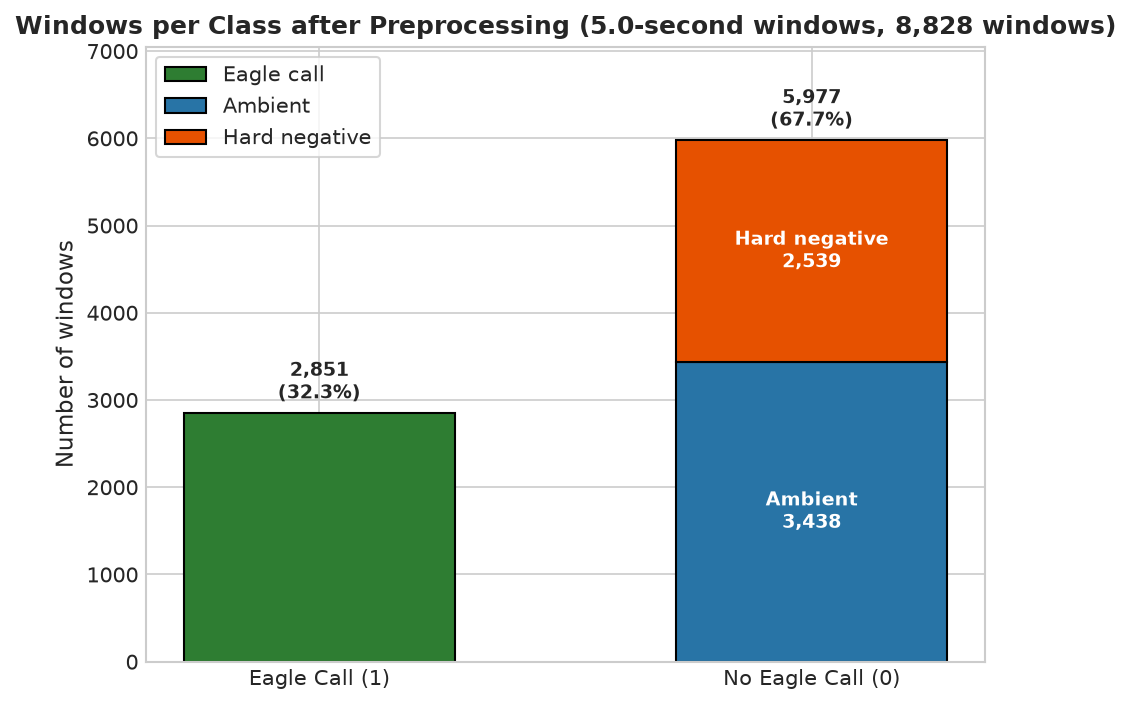

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/preprocess/outputs/figures/5s-window-category-distribution.png


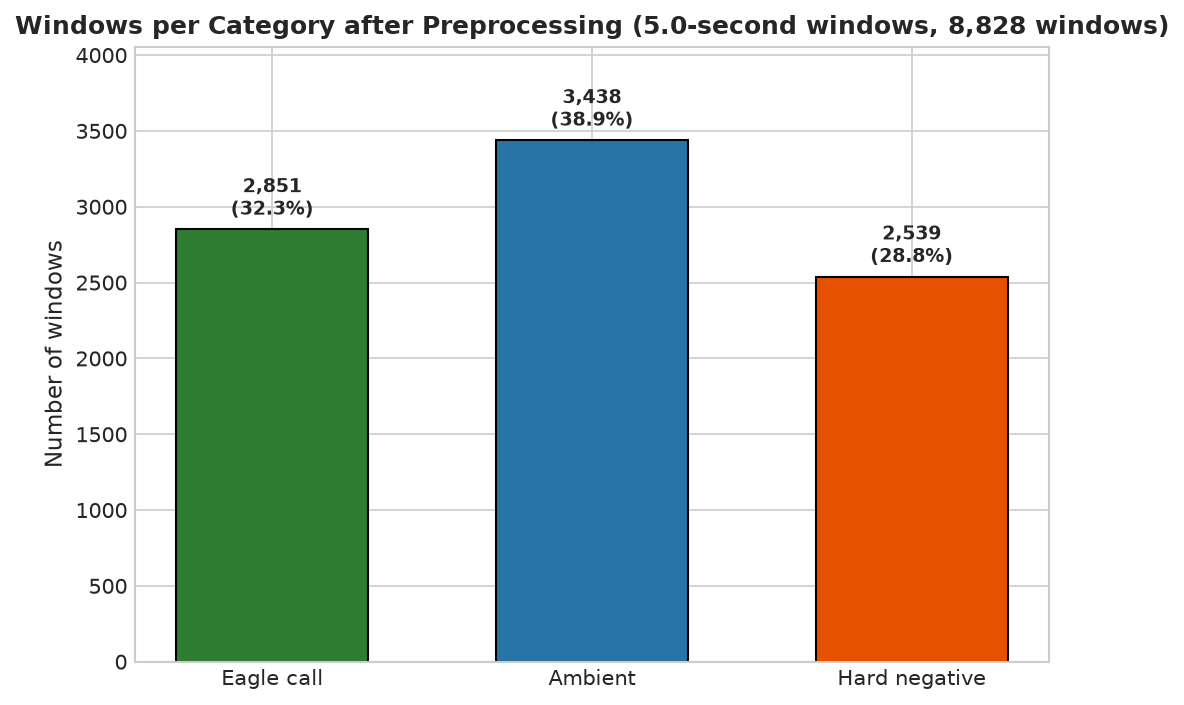

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/preprocess/outputs/figures/5s-eagle-site-distribution.png


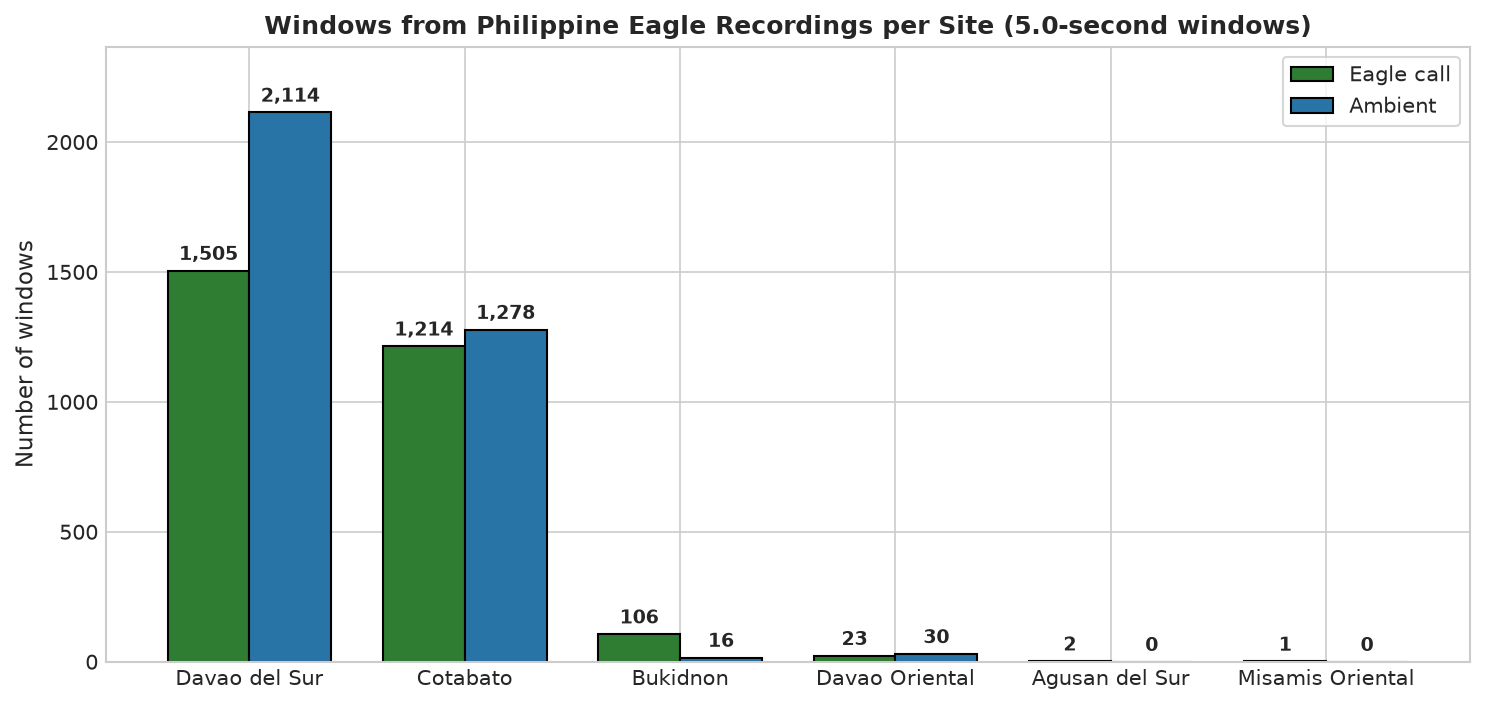

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/preprocess/outputs/figures/5s-hard-negative-species-distribution.png


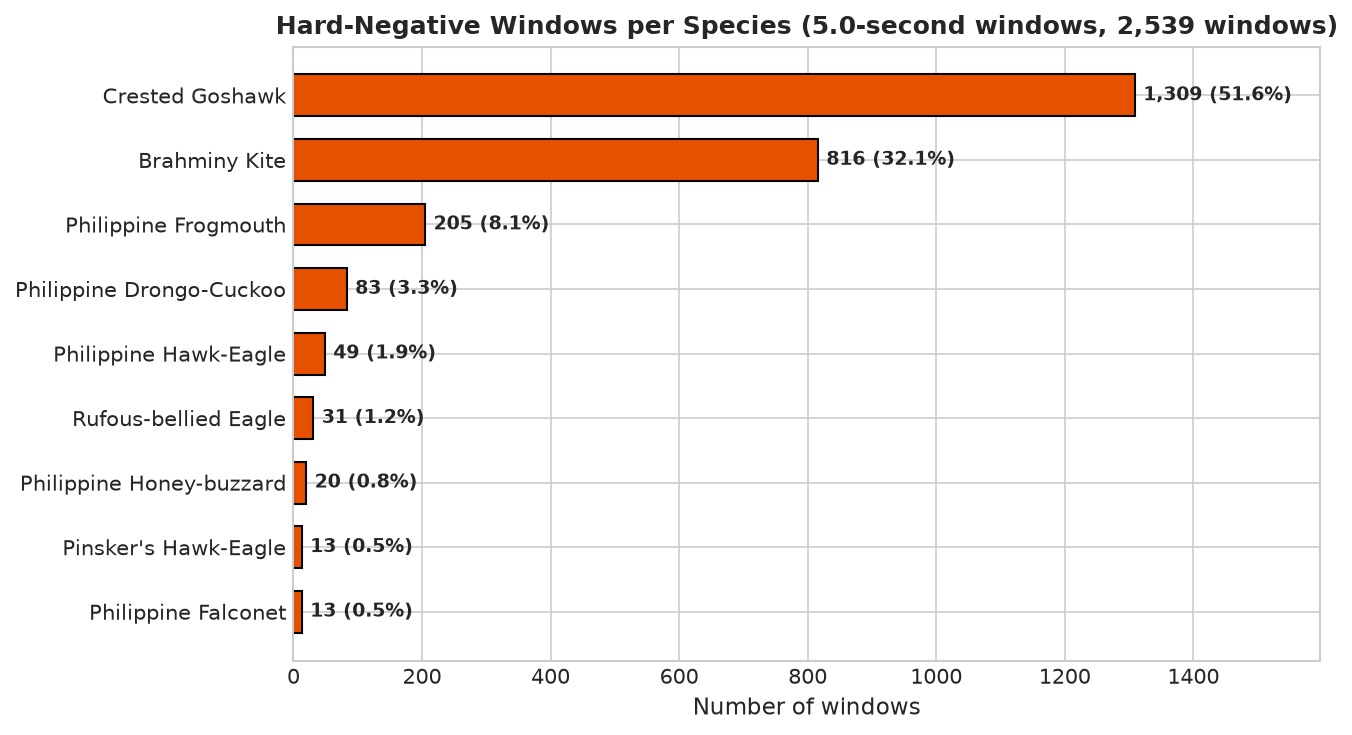

Windows shown: 8,828 (222 ambiguous windows left out)


,windows
group,
Eagle call,2851
Ambient,3438
Hard negative,2539


group,Eagle call,Ambient
site,,
Davao del Sur,1505,2114
Cotabato,1214,1278
Bukidnon,106,16
Davao Oriental,23,30
Agusan del Sur,2,0
Misamis Oriental,1,0


In [10]:
# Distributions of the 5.0-second windows after preprocessing
plot_window_distributions(df_metadata_5s, "5s", "5.0-second windows")


## 5. Preprocessing: 3.0-Second Windows


### 5.1. Slice 3.0-Second Philippine Eagle Recordings


In [11]:
# Caching guard for eagle 3s slices
existing_eagle_3s = list(OUTPUT_AUDIO_3S.glob("converted_*.wav"))

if len(existing_eagle_3s) > 0 and METADATA_3S_PATH.exists():
    print(f"Caching Guard: Found {len(existing_eagle_3s)} cached Eagle 3.0s slices. Loading records...")
    df_existing_3s = pd.read_csv(METADATA_3S_PATH)
    if "dataset_source" in df_existing_3s.columns:
        records_eagle_3s = df_existing_3s[df_existing_3s["dataset_source"] == "eagle-audios"].to_dict("records")
    else:
        records_eagle_3s = df_existing_3s.to_dict("records")
        for r in records_eagle_3s:
            r["dataset_source"] = "eagle-audios"
            r["species"] = "Philippine Eagle" if r.get("is_eagle") else "Philippine Eagle Territory (Ambient)"
            r["scientific_name"] = "Pithecophaga jefferyi" if r.get("is_eagle") else "none"
else:
    records_eagle_3s = slice_eagle_dataset(
        stems=valid_eagle_stems,
        audio_map=eagle_audio_dict,
        table_map=eagle_table_dict,
        meta_lookup_dict=eagle_meta_lookup,
        window_size=WINDOW_SIZE_3S,
        hop_size=HOP_SIZE_3S,
        target_sr=TARGET_SR,
        call_overlap_thresh=CALL_OVERLAP_THRESH,
        output_audio_dir=OUTPUT_AUDIO_3S,
        relative_dir_name="data/preprocessed/3-seconds/audios"
    )

print(f"Total valid Eagle 3.0s slices: {len(records_eagle_3s)}")


Caching Guard: Found 8806 cached Eagle 3.0s slices. Loading records...
Total valid Eagle 3.0s slices: 8806


### 5.2. Slice 3.0-Second Hard Negatives with Activity Filtering


In [12]:
# Caching guard for hard negatives 3s slices
existing_hardneg_3s = list(OUTPUT_AUDIO_3S.glob("hardneg_*.wav"))

if len(existing_hardneg_3s) > 0 and METADATA_3S_PATH.exists():
    df_existing_3s = pd.read_csv(METADATA_3S_PATH)
    if "dataset_source" in df_existing_3s.columns and (df_existing_3s["dataset_source"] == "hard-negatives").sum() > 0:
        print(f"Caching Guard: Found {len(existing_hardneg_3s)} cached Hard Negative 3.0s slices. Loading records...")
        records_hardneg_3s = df_existing_3s[df_existing_3s["dataset_source"] == "hard-negatives"].to_dict("records")
    else:
        records_hardneg_3s = slice_hard_negatives_dataset(
            audio_files=hard_neg_files,
            hard_neg_lookup_dict=hard_neg_lookup,
            window_size=WINDOW_SIZE_3S,
            hop_size=HOP_SIZE_3S,
            target_sr=TARGET_SR,
            call_overlap_thresh=CALL_OVERLAP_THRESH,
            output_audio_dir=OUTPUT_AUDIO_3S,
            relative_dir_name="data/preprocessed/3-seconds/audios"
        )
else:
    records_hardneg_3s = slice_hard_negatives_dataset(
        audio_files=hard_neg_files,
        hard_neg_lookup_dict=hard_neg_lookup,
        window_size=WINDOW_SIZE_3S,
        hop_size=HOP_SIZE_3S,
        target_sr=TARGET_SR,
        call_overlap_thresh=CALL_OVERLAP_THRESH,
        output_audio_dir=OUTPUT_AUDIO_3S,
        relative_dir_name="data/preprocessed/3-seconds/audios"
    )

print(f"Total valid Hard Negatives 3.0s slices: {len(records_hardneg_3s)}")

Caching Guard: Found 2485 cached Hard Negative 3.0s slices. Loading records...
Total valid Hard Negatives 3.0s slices: 2485


### 5.3. Consolidate and Save 3.0-Second Preprocessed Metadata


In [13]:
# Consolidate Eagle and Hard Negative records into unified DataFrame
df_metadata_3s = pd.DataFrame(records_eagle_3s + records_hardneg_3s)

# Save to metadata CSV
df_metadata_3s.to_csv(METADATA_3S_PATH, index=False)
print(f"Successfully saved 3.0s metadata to: {METADATA_3S_PATH}")
print(f"Total 3.0s slices: {len(df_metadata_3s)}")
display(df_metadata_3s.head(5))


Successfully saved 3.0s metadata to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/3-seconds/metadata.csv
Total 3.0s slices: 11291


,file_name,file_path,source_audio,site,age_sex,start_time,end_time,duration,sample_rate,is_eagle,label,call_types,call_ids,call_uid,call_overlap_ratio,has_ambiguous,species,scientific_name,dataset_source
0,converted_135598_00004.5_00007.5.wav,data/preprocessed/3-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,4.5,7.5,3.0,22050,True,1,PhilEagle_long,2,converted_135598_call_2,1.0000,False,Philippine Eagle,Pithecophaga jefferyi,eagle-audios
1,converted_135598_00006.0_00009.0.wav,data/preprocessed/3-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,6.0,9.0,3.0,22050,True,1,PhilEagle_long,2;3,converted_135598_call_2;converted_135598_call_3,1.0000,False,Philippine Eagle,Pithecophaga jefferyi,eagle-audios
2,converted_135598_00007.5_00010.5.wav,data/preprocessed/3-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,7.5,10.5,3.0,22050,True,1,PhilEagle_long,3,converted_135598_call_3,1.0000,False,Philippine Eagle,Pithecophaga jefferyi,eagle-audios
3,converted_135598_00009.0_00012.0.wav,data/preprocessed/3-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,9.0,12.0,3.0,22050,True,1,PhilEagle_long,4,converted_135598_call_4,0.6799,False,Philippine Eagle,Pithecophaga jefferyi,eagle-audios
4,converted_135598_00010.5_00013.5.wav,data/preprocessed/3-seconds/audios/converted_1...,converted_135598.wav,Davao del Sur,Adult – 1; Juvenile Female – 1,10.5,13.5,3.0,22050,True,1,PhilEagle_long,4,converted_135598_call_4,1.0000,False,Philippine Eagle,Pithecophaga jefferyi,eagle-audios


### 5.4. Analyze 3.0-Second Class, Species, and Site Distributions


In [14]:
# Analyze class balance, 3-way categories, and format distribution for 3.0s dataset
df_metadata_3s["category"] = df_metadata_3s.apply(get_slice_category, axis=1)
df_metadata_3s["source_format"] = df_metadata_3s["source_audio"].apply(lambda s: Path(str(s)).suffix.lower())

print("=" * 65)
print("3.0-SECOND DATASET SUMMARY & DISTRIBUTIONS")
print("=" * 65)
print(f"Total Preprocessed Slices: {len(df_metadata_3s)}")
print("\n1. Binary Labels (label):")
print(df_metadata_3s["label"].value_counts().rename({1: "Eagle Call (1)", 0: "No Eagle (0)"}))
print("\n2. Three-Way Category Distribution:")
print(df_metadata_3s["category"].value_counts())
print("\n3. Source Audio File Format Distribution:")
print(df_metadata_3s["source_format"].value_counts())
print(f"Output Slice Format: 100% .wav (PCM_16 @ {TARGET_SR} Hz)")
print("\n4. Top Species Breakdown:")
print(df_metadata_3s["species"].value_counts().head(10))
print("=" * 65)


3.0-SECOND DATASET SUMMARY & DISTRIBUTIONS
Total Preprocessed Slices: 11291

1. Binary Labels (label):
label
No Eagle (0)      7893
Eagle Call (1)    3398
Name: count, dtype: int64

2. Three-Way Category Distribution:
category
Normal Negative (Eagle Ambient)    5408
Philippine Eagle Call              3398
Hard Negative                      2485
Name: count, dtype: int64

3. Source Audio File Format Distribution:
source_format
.wav    10985
.mp3      162
.m4a      144
Name: count, dtype: int64
Output Slice Format: 100% .wav (PCM_16 @ 22050 Hz)

4. Top Species Breakdown:
species
Philippine Eagle Territory (Ambient)    5408
Philippine Eagle                        3398
Crested Goshawk                         1267
Brahminy Kite                            821
Philippine Frogmouth                     198
Philippine Drongo-Cuckoo                  77
Philippine Hawk-Eagle                     46
Rufous-bellied Eagle                      33
Philippine Honey-buzzard                  20
Pinsker's H

### 5.5. Visualize 3.0-Second Window Distributions (Class, Category, Site, and Species)

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/preprocess/outputs/figures/3s-class-distribution.png


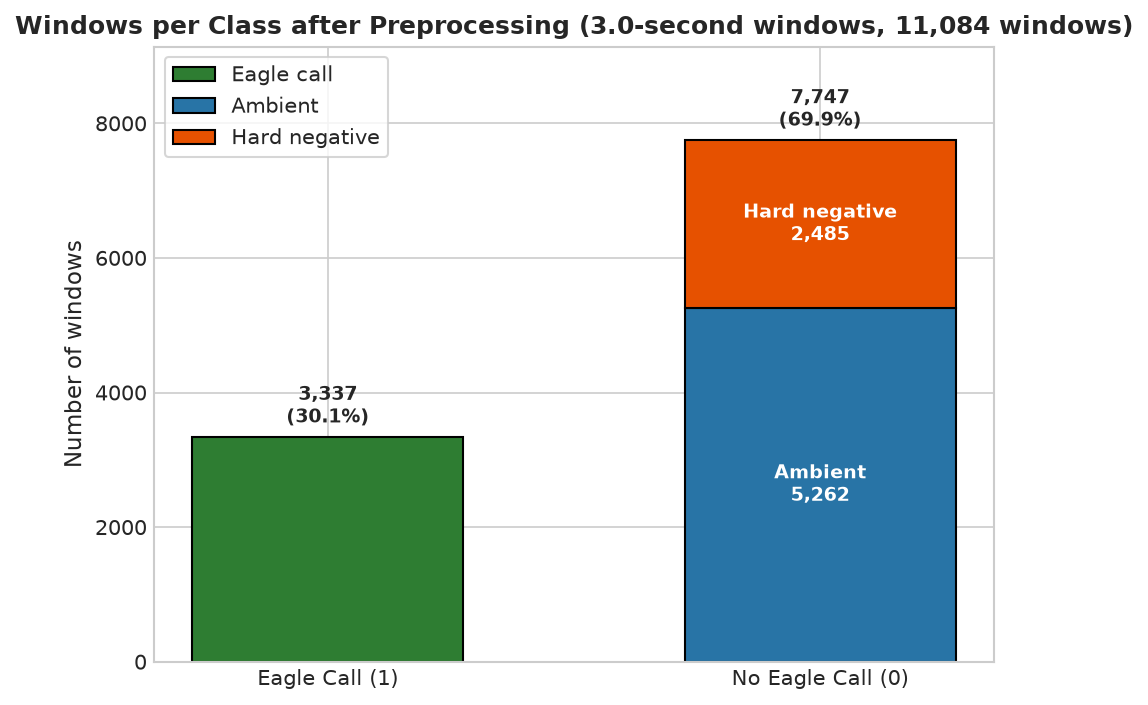

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/preprocess/outputs/figures/3s-window-category-distribution.png


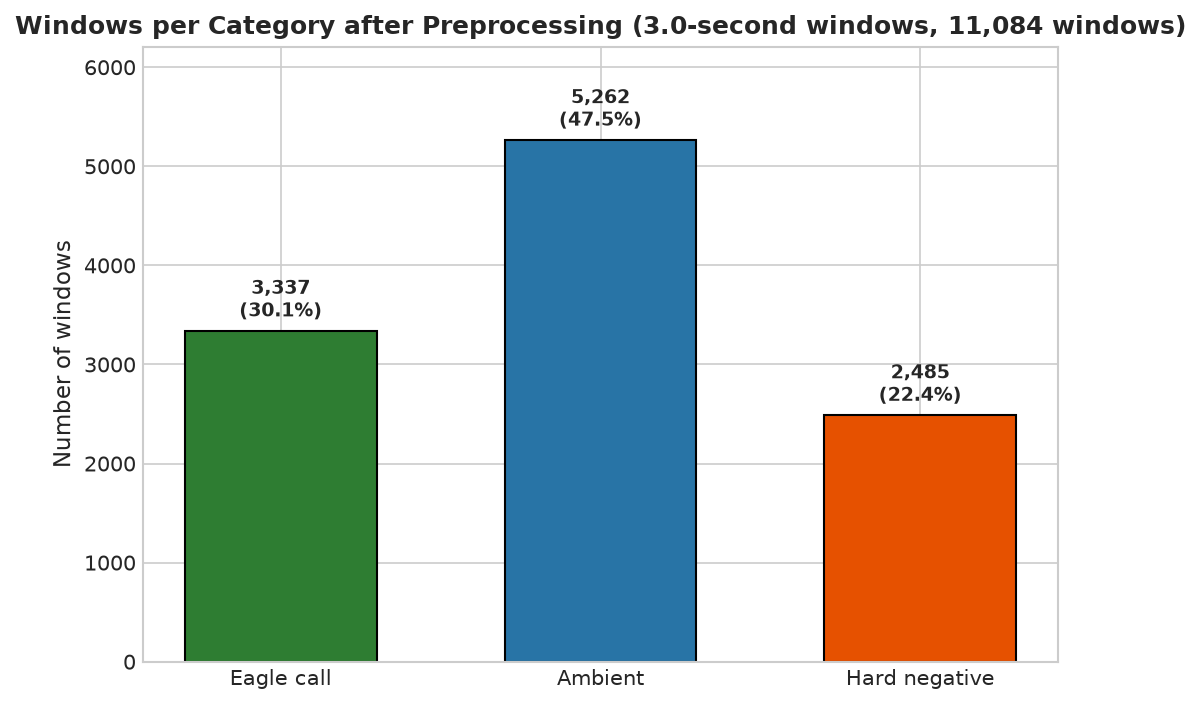

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/preprocess/outputs/figures/3s-eagle-site-distribution.png


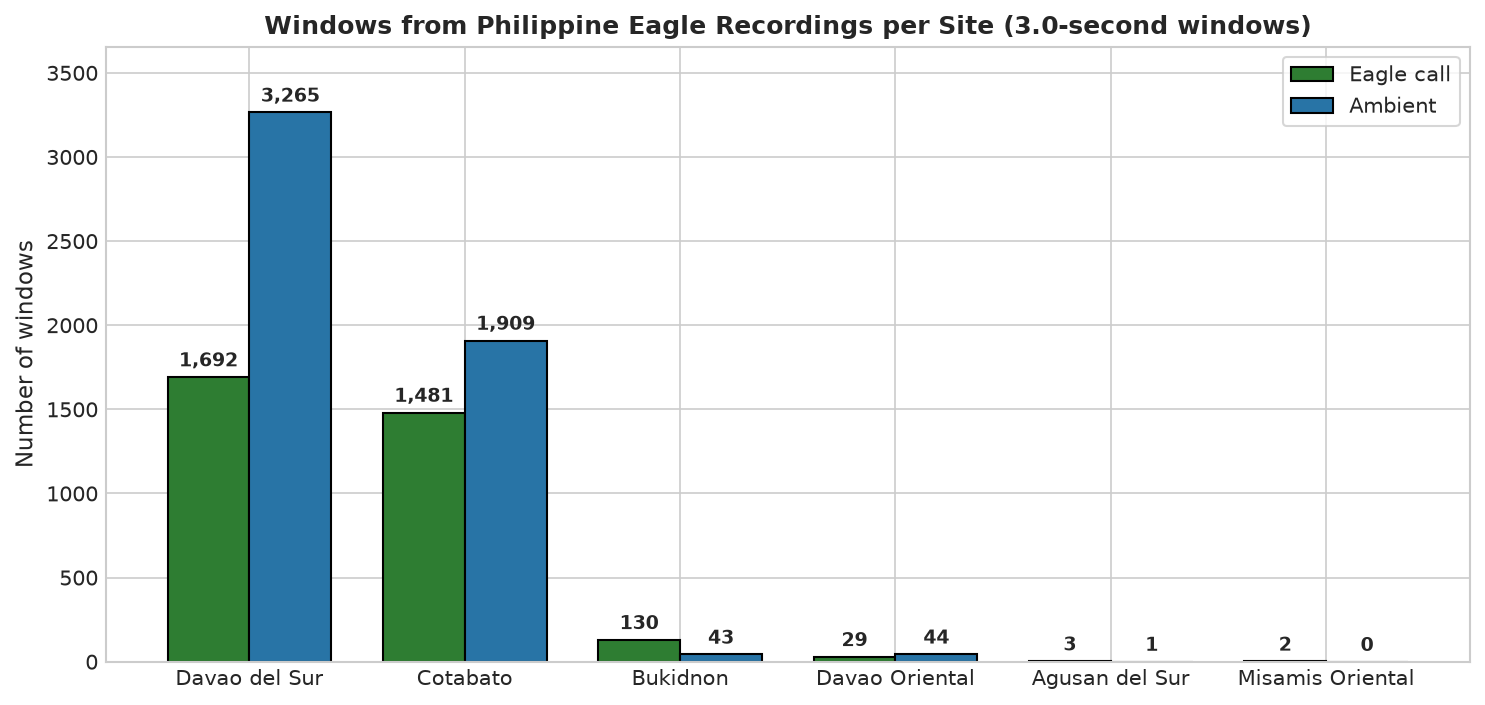

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/preprocess/outputs/figures/3s-hard-negative-species-distribution.png


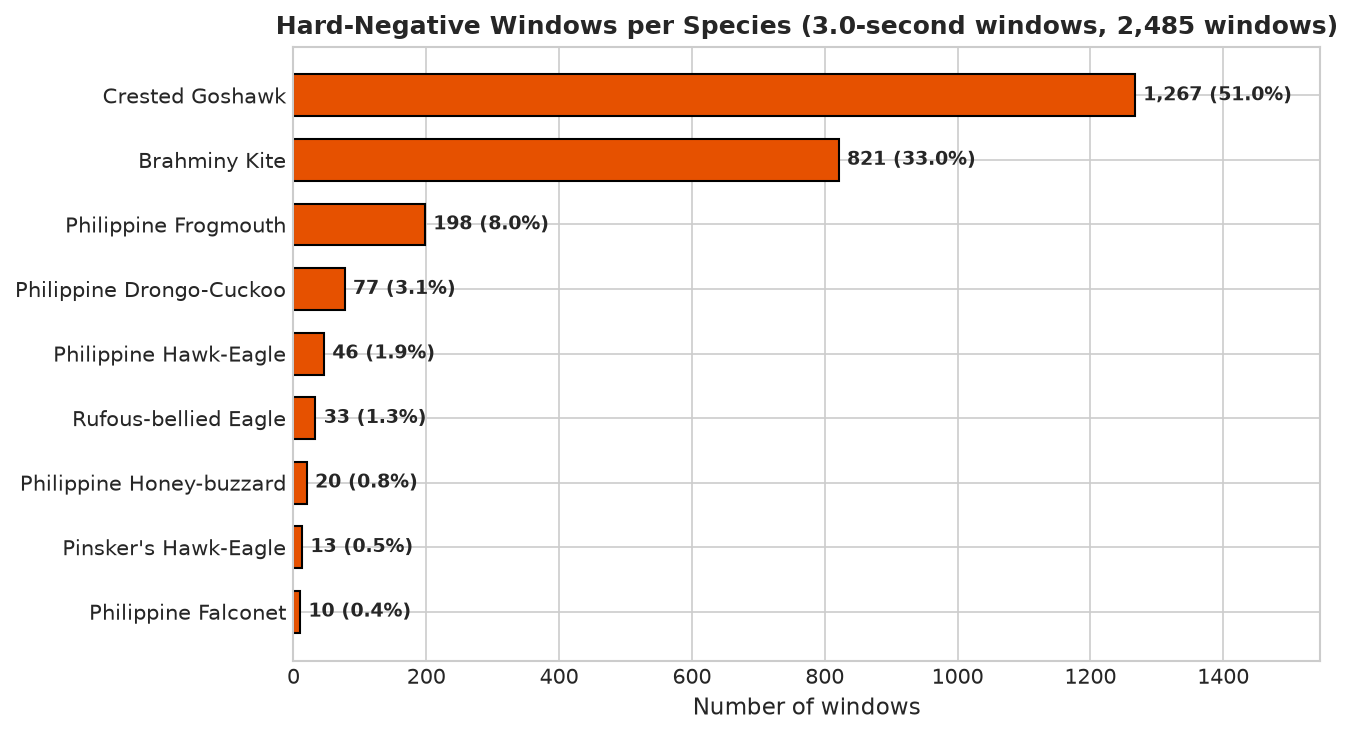

Windows shown: 11,084 (207 ambiguous windows left out)


,windows
group,
Eagle call,3337
Ambient,5262
Hard negative,2485


group,Eagle call,Ambient
site,,
Davao del Sur,1692,3265
Cotabato,1481,1909
Bukidnon,130,43
Davao Oriental,29,44
Agusan del Sur,3,1
Misamis Oriental,2,0


In [15]:
# Distributions of the 3.0-second windows after preprocessing
plot_window_distributions(df_metadata_3s, "3s", "3.0-second windows")


## 6. Comparative Analysis and Visualizations


### 6.1. Side-by-Side Slicing Statistics Comparison


In [16]:
# Summary comparison table across 5.0s and 3.0s datasets
comp_metrics = {
    "Total Slices": [len(df_metadata_5s), len(df_metadata_3s)],
    "Philippine Eagle Calls (label=1)": [(df_metadata_5s["category"] == "Philippine Eagle Call").sum(), (df_metadata_3s["category"] == "Philippine Eagle Call").sum()],
    "Normal Negatives (Eagle Ambient)": [(df_metadata_5s["category"] == "Normal Negative (Eagle Ambient)").sum(), (df_metadata_3s["category"] == "Normal Negative (Eagle Ambient)").sum()],
    "Hard Negatives (Sympatric Birds)": [(df_metadata_5s["category"] == "Hard Negative").sum(), (df_metadata_3s["category"] == "Hard Negative").sum()],
    "Total Negatives (label=0)": [(df_metadata_5s["label"] == 0).sum(), (df_metadata_3s["label"] == 0).sum()],
    "Distinct Raptor / Bird Species": [df_metadata_5s["species"].nunique(), df_metadata_3s["species"].nunique()],
    "Source Format: .wav": [(df_metadata_5s["source_format"] == ".wav").sum(), (df_metadata_3s["source_format"] == ".wav").sum()],
    "Source Format: .mp3": [(df_metadata_5s["source_format"] == ".mp3").sum(), (df_metadata_3s["source_format"] == ".mp3").sum()],
    "Source Format: .m4a": [(df_metadata_5s["source_format"] == ".m4a").sum(), (df_metadata_3s["source_format"] == ".m4a").sum()]
}

df_scale_comparison = pd.DataFrame(comp_metrics, index=["5.0-Second Scale", "3.0-Second Scale"]).T
print("Comparative Multi-Scale Dataset Slicing Overview:")
display(df_scale_comparison)


Comparative Multi-Scale Dataset Slicing Overview:


,5.0-Second Scale,3.0-Second Scale
Total Slices,9050,11291
Philippine Eagle Calls (label=1),2963,3398
Normal Negatives (Eagle Ambient),3548,5408
Hard Negatives (Sympatric Birds),2539,2485
Total Negatives (label=0),6087,7893
Distinct Raptor / Bird Species,11,11
Source Format: .wav,8743,10985
Source Format: .mp3,157,162
Source Format: .m4a,150,144


### 6.2. Comparative Class and Species Distribution Visualizations


Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/preprocess/outputs/figures/class-and-species-distribution.png


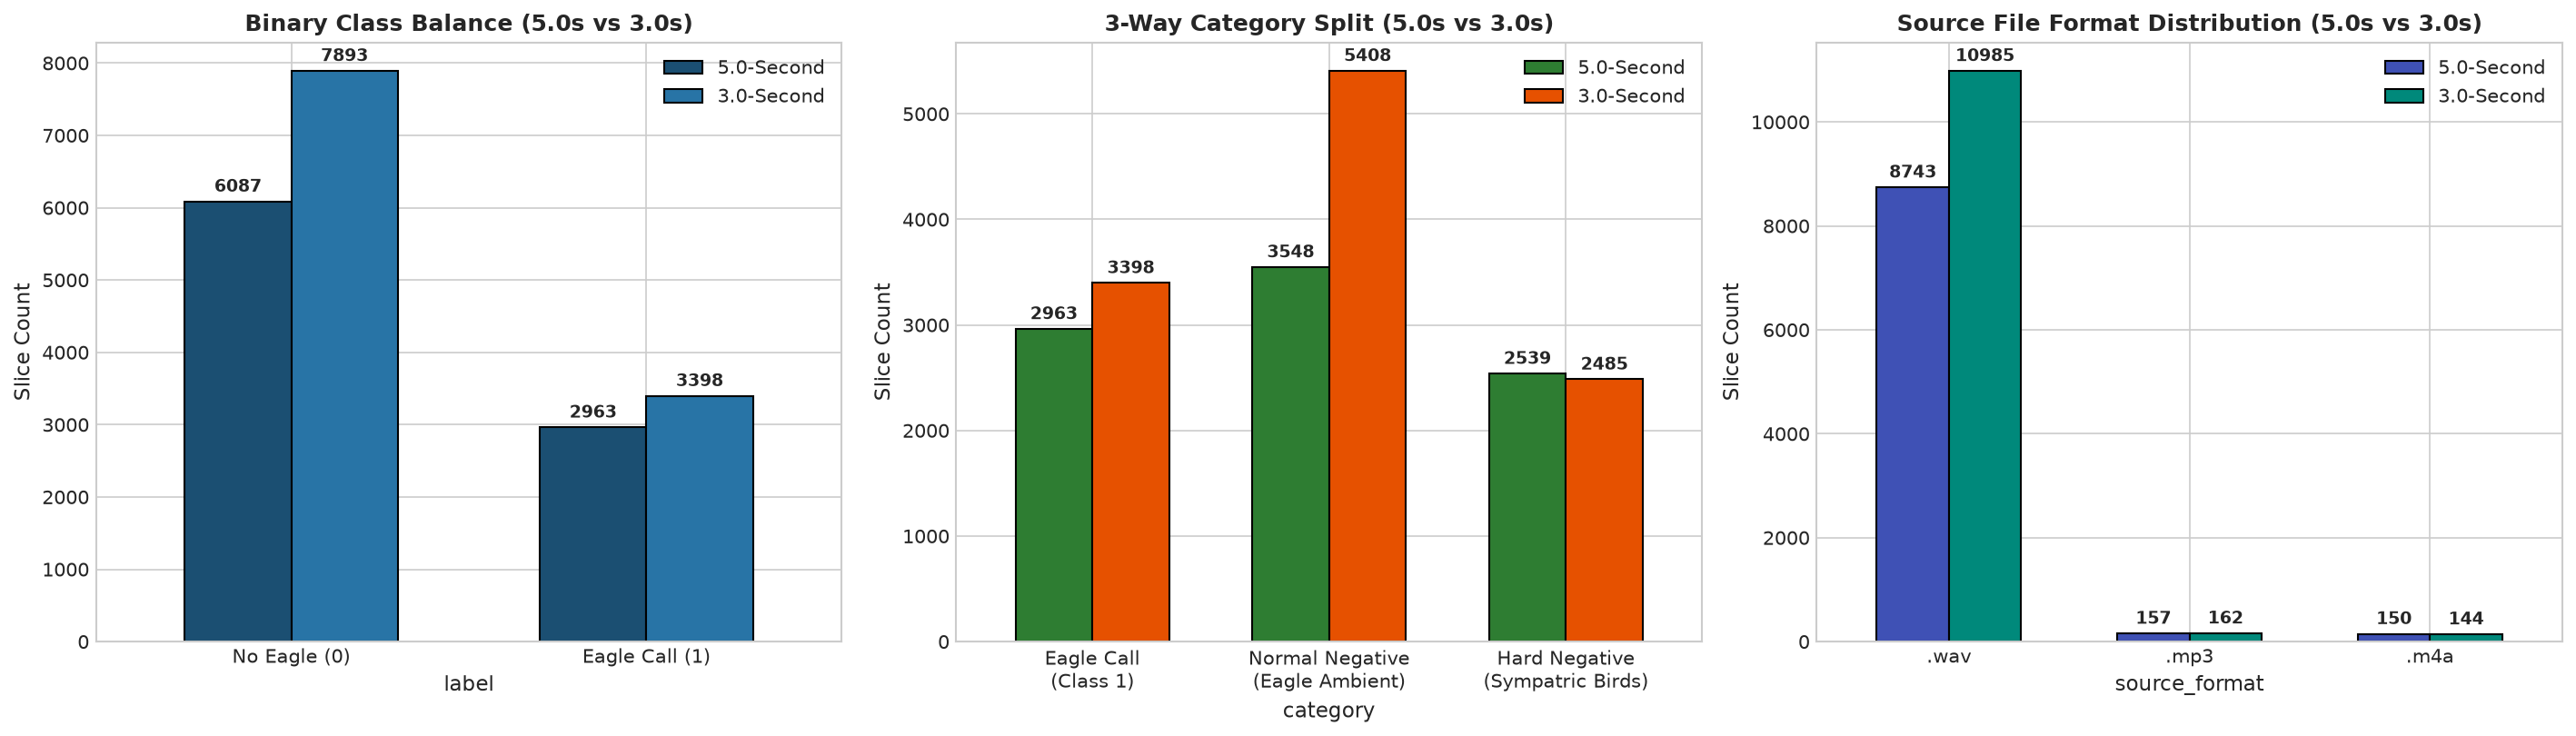

In [17]:
# Plot comparative class, 3-way category, and file format distributions across 5.0s and 3.0s
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(19, 5.5))

# Panel 1: Binary class balance comparison
class_df = pd.DataFrame({
    "5.0-Second": df_metadata_5s["label"].value_counts().rename({1: "Eagle Call (1)", 0: "No Eagle (0)"}),
    "3.0-Second": df_metadata_3s["label"].value_counts().rename({1: "Eagle Call (1)", 0: "No Eagle (0)"})
})
class_df.plot(kind="bar", color=["#1b4f72", "#2874a6"], ax=ax1, edgecolor="black", width=0.6)
ax1.set_title("Binary Class Balance (5.0s vs 3.0s)", fontweight="bold")
ax1.set_ylabel("Slice Count")
ax1.tick_params(axis="x", rotation=0)
for p in ax1.patches:
    h = p.get_height()
    if h > 0:
        ax1.annotate(f"{int(h)}", (p.get_x() + p.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

# Panel 2: Three-Way Category Comparison (Eagle Call vs Normal Negative vs Hard Negative)
cats_order = ["Philippine Eagle Call", "Normal Negative (Eagle Ambient)", "Hard Negative"]
cat_compare_df = pd.DataFrame({
    "5.0-Second": df_metadata_5s["category"].value_counts().reindex(cats_order),
    "3.0-Second": df_metadata_3s["category"].value_counts().reindex(cats_order)
})
cat_compare_df.plot(kind="bar", color=["#2e7d32", "#e65100"], ax=ax2, edgecolor="black", width=0.65)
ax2.set_title("3-Way Category Split (5.0s vs 3.0s)", fontweight="bold")
ax2.set_ylabel("Slice Count")
ax2.set_xticklabels(["Eagle Call\n(Class 1)", "Normal Negative\n(Eagle Ambient)", "Hard Negative\n(Sympatric Birds)"], rotation=0)
for p in ax2.patches:
    h = p.get_height()
    if h > 0:
        ax2.annotate(f"{int(h)}", (p.get_x() + p.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

# Panel 3: Source Audio File Format Distribution (.wav, .mp3, .m4a)
fmt_order = [".wav", ".mp3", ".m4a"]
fmt_compare_df = pd.DataFrame({
    "5.0-Second": df_metadata_5s["source_format"].value_counts().reindex(fmt_order),
    "3.0-Second": df_metadata_3s["source_format"].value_counts().reindex(fmt_order)
})
fmt_compare_df.plot(kind="bar", color=["#3f51b5", "#00897b"], ax=ax3, edgecolor="black", width=0.6)
ax3.set_title("Source File Format Distribution (5.0s vs 3.0s)", fontweight="bold")
ax3.set_ylabel("Slice Count")
ax3.set_xticklabels([".wav", ".mp3", ".m4a"], rotation=0)
for p in ax3.patches:
    h = p.get_height()
    if h > 0:
        ax3.annotate(f"{int(h)}", (p.get_x() + p.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
output_path = FIGURES_DIR / "class-and-species-distribution.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {output_path}")
plt.show()


### 6.3. Hard Negatives Species Representation in Slices


Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/preprocess/outputs/figures/hard-negatives-slice-breakdown.png


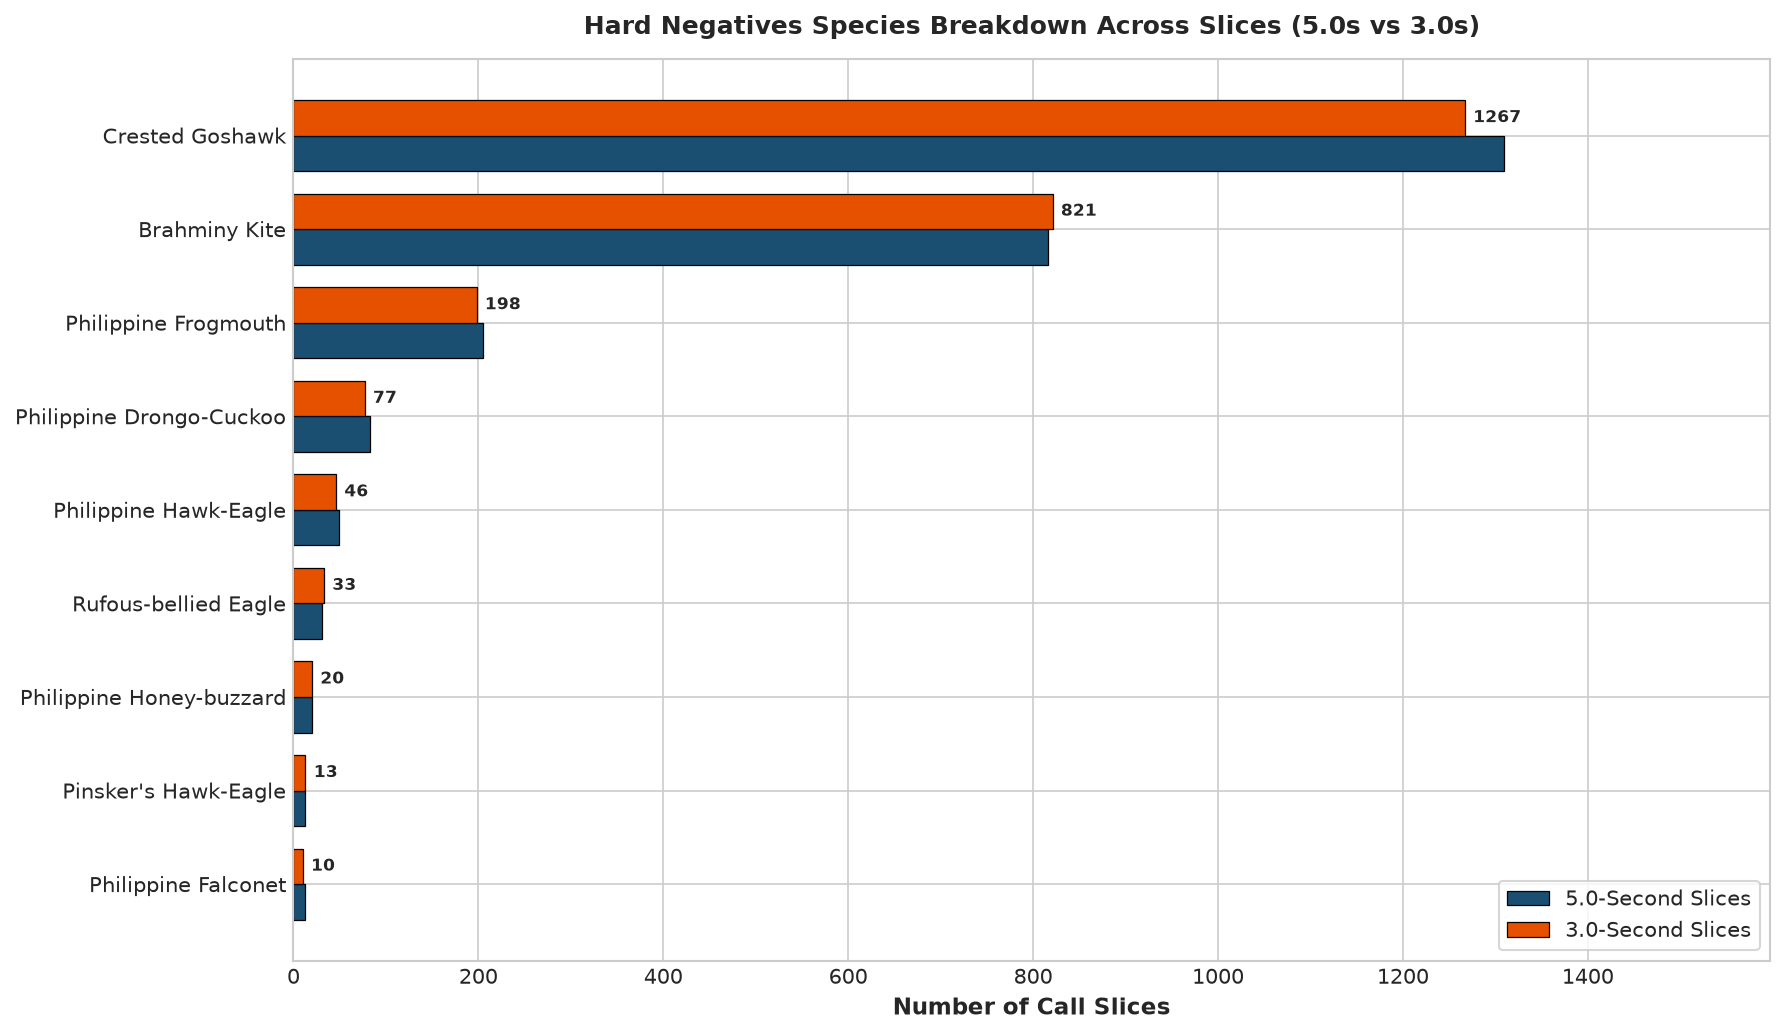

In [18]:
# Species representation within hard-negatives slices across both 5.0s and 3.0s
df_hard_negs_5s = df_metadata_5s[df_metadata_5s["dataset_source"] == "hard-negatives"]
df_hard_negs_3s = df_metadata_3s[df_metadata_3s["dataset_source"] == "hard-negatives"]

hard_5s_counts = df_hard_negs_5s["species"].value_counts()
hard_3s_counts = df_hard_negs_3s["species"].value_counts()

# Combined DataFrame sorted by 3.0s frequency
species_union = hard_3s_counts.index.union(hard_5s_counts.index)
df_species_compare = pd.DataFrame({
    "5.0-Second": hard_5s_counts.reindex(species_union, fill_value=0),
    "3.0-Second": hard_3s_counts.reindex(species_union, fill_value=0)
}).sort_values("3.0-Second", ascending=True)

fig, ax = plt.subplots(figsize=(12, 7))
y_indices = np.arange(len(df_species_compare))
bar_height = 0.38

bars_5s = ax.barh(y_indices - bar_height / 2, df_species_compare["5.0-Second"], height=bar_height,
                  label="5.0-Second Slices", color="#1b4f72", edgecolor="black", linewidth=0.6)
bars_3s = ax.barh(y_indices + bar_height / 2, df_species_compare["3.0-Second"], height=bar_height,
                  label="3.0-Second Slices", color="#e65100", edgecolor="black", linewidth=0.6)

ax.set_yticks(y_indices)
ax.set_yticklabels(df_species_compare.index, fontsize=10)
ax.set_xlabel("Number of Call Slices", fontweight="bold")
ax.set_title("Hard Negatives Species Breakdown Across Slices (5.0s vs 3.0s)", fontweight="bold", pad=12)
ax.legend(loc="lower right", frameon=True)

max_val = max(df_species_compare["5.0-Second"].max(), df_species_compare["3.0-Second"].max())
ax.set_xlim(0, max_val * 1.22)

for bar in bars_3s:
    w = bar.get_width()
    if w > 0:
        ax.annotate(f"{int(w)}", xy=(w, bar.get_y() + bar.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points", ha="left", va="center", fontsize=8, fontweight="bold")

plt.tight_layout()
output_path = FIGURES_DIR / "hard-negatives-slice-breakdown.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {output_path}")
plt.show()


### 6.4. Pipeline Summary and Downstream Feature Extraction Recommendations


In [19]:
# Summary metrics and recommendations for downstream models
print("=" * 80)
print("PREPROCESSING PIPELINE SUMMARY & RECOMMENDATIONS")
print("=" * 80)
print(f"1. Primary Target Scale:  5.0 Seconds ({WINDOW_SIZE_5S}s window, {HOP_SIZE_5S}s hop at {TARGET_SR} Hz)")
print(f"   * Total 5.0s Slices:   {len(df_metadata_5s):,}")
print(f"   * Eagle Calls (1):     {(df_metadata_5s['label'] == 1).sum():,}")
print(f"   * Total Negatives (0): {(df_metadata_5s['label'] == 0).sum():,} (includes territory ambient + {df_hard_negs_5s['species'].nunique()} hard-negative raptor species)")
print()
print(f"2. Secondary Scale:       3.0 Seconds ({WINDOW_SIZE_3S}s window, {HOP_SIZE_3S}s hop at {TARGET_SR} Hz)")
print(f"   * Total 3.0s Slices:   {len(df_metadata_3s):,}")
print()
print("3. Downstream Feature Extraction (Notebook 03):")
print(f"   * Spectrograms and PCEN features will be extracted directly from: {OUTPUT_AUDIO_5S}")
print(f"   * Metadata manifests saved cleanly at: {METADATA_5S_PATH} and {METADATA_3S_PATH}")
print("=" * 80)


PREPROCESSING PIPELINE SUMMARY & RECOMMENDATIONS
1. Primary Target Scale:  5.0 Seconds (5.0s window, 2.0s hop at 22050 Hz)
   * Total 5.0s Slices:   9,050
   * Eagle Calls (1):     2,963
   * Total Negatives (0): 6,087 (includes territory ambient + 9 hard-negative raptor species)

2. Secondary Scale:       3.0 Seconds (3.0s window, 1.5s hop at 22050 Hz)
   * Total 3.0s Slices:   11,291

3. Downstream Feature Extraction (Notebook 03):
   * Spectrograms and PCEN features will be extracted directly from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/5-seconds/audios
   * Metadata manifests saved cleanly at: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/5-seconds/metadata.csv and /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/3-seconds/metadata.csv


## 7. Hard-Negative Recording Exclusions

Counts the raw hard-negative recordings that gave no window and the step where each one stopped. It needs sections 1 to 3 only and does not change the sliced audio or the metadata.

In [20]:
# Find out why some hard-negative recordings gave no window (reads raw audio only, writes no audio)
STATISTICS_DIR = OUTPUTS_DIR / "statistics"
STATISTICS_DIR.mkdir(parents=True, exist_ok=True)

EXCLUSIONS_CSV_PATH = OUTPUTS_DIR / "hard-negative-recording-exclusions.csv"
EXCLUSIONS_TXT_PATH = STATISTICS_DIR / "hard-negative-recording-exclusions.txt"

WINDOW_SETTINGS = [
    ("3s", WINDOW_SIZE_3S, HOP_SIZE_3S, METADATA_3S_PATH),
    ("5s", WINDOW_SIZE_5S, HOP_SIZE_5S, METADATA_5S_PATH),
]

df_exclusions = diagnose_hard_negative_recordings(
    audio_files=hard_neg_files,
    hard_neg_lookup_dict=hard_neg_lookup,
    window_settings=[(tag, window_size, hop_size) for tag, window_size, hop_size, _ in WINDOW_SETTINGS],
    target_sr=TARGET_SR,
    call_overlap_thresh=CALL_OVERLAP_THRESH,
)
df_exclusions.to_csv(EXCLUSIONS_CSV_PATH, index=False)

KEPT_OUTCOME = "Kept (at least one window)"
report_lines = [
    "Hard-negative recording exclusions",
    "=" * 80,
    f"Raw hard-negative recordings: {len(df_exclusions)}",
    "Each recording is counted once, at the first step where it stops.",
]

for tag, window_size, hop_size, metadata_path in WINDOW_SETTINGS:
    outcome_col = f"outcome_{tag}"
    outcome_counts = df_exclusions[outcome_col].value_counts()
    kept_now = set(df_exclusions.loc[df_exclusions[outcome_col] == KEPT_OUTCOME, "source_audio"])

    report_lines += ["", f"{window_size}-second windows ({hop_size}-second hop)", "-" * 80]
    for outcome, count in outcome_counts.items():
        report_lines.append(f"{outcome:<62} {count:>5} ({100 * count / len(df_exclusions):5.1f}%)")
    report_lines.append(f"{'Excluded in total':<62} {len(df_exclusions) - len(kept_now):>5}")

    # Compare with the recordings that are in the saved metadata
    if metadata_path.exists():
        df_saved = pd.read_csv(metadata_path)
        kept_saved = set(df_saved.loc[df_saved["dataset_source"] == "hard-negatives", "source_audio"])
        report_lines.append(
            f"Recordings in saved metadata: {len(kept_saved)} | kept here: {len(kept_now)} | "
            f"same set: {'yes' if kept_saved == kept_now else 'NO'}"
        )
        if kept_saved != kept_now:
            report_lines.append(f"  Only in saved metadata: {len(kept_saved - kept_now)} | only here: {len(kept_now - kept_saved)}")
    else:
        report_lines.append(f"Saved metadata not found at {metadata_path.name}; comparison skipped.")

    excluded = df_exclusions[df_exclusions[outcome_col] != KEPT_OUTCOME]
    if len(excluded) > 0:
        by_species = pd.crosstab(df_exclusions["species"], df_exclusions[outcome_col] == KEPT_OUTCOME)
        by_species = by_species.reindex(columns=[True, False], fill_value=0)
        by_species.columns = ["Kept", "Excluded"]
        report_lines += ["", "Recordings per species:", by_species.to_string()]
        report_lines += [
            "",
            f"Duration of excluded recordings: median {excluded['duration_sec'].median():.1f} s "
            f"(min {excluded['duration_sec'].min():.1f} s, max {excluded['duration_sec'].max():.1f} s)",
            f"Duration of kept recordings:     median {df_exclusions.loc[df_exclusions[outcome_col] == KEPT_OUTCOME, 'duration_sec'].median():.1f} s",
        ]

load_errors = df_exclusions[df_exclusions["load_error"] != ""]
if len(load_errors) > 0:
    report_lines += ["", "Recordings that could not be loaded:"]
    report_lines += [f"  {r.source_audio}: {r.load_error}" for r in load_errors.itertuples()]

report_text = "\n".join(report_lines)
EXCLUSIONS_TXT_PATH.write_text(report_text + "\n")
print(report_text)
print(f"\nSaved: {EXCLUSIONS_CSV_PATH.relative_to(EXPERIMENT_DIR)}")
print(f"Saved: {EXCLUSIONS_TXT_PATH.relative_to(EXPERIMENT_DIR)}")

Checking Hard Negative recordings:   9%|█▉                   | 65/707 [00:02<00:22, 28.22it/s][src/libmpg123/id3.c:process_extra():684] error: No extra frame text / valid description?
[src/libmpg123/id3.c:process_extra():684] error: No extra frame text / valid description?
Checking Hard Negative recordings: 100%|████████████████████| 707/707 [00:19<00:00, 36.33it/s]


Hard-negative recording exclusions
Raw hard-negative recordings: 707
Each recording is counted once, at the first step where it stops.

3.0-second windows (1.5-second hop)
--------------------------------------------------------------------------------
Kept (at least one window)                                       503 ( 71.1%)
No vocalization found by the energy filter                       190 ( 26.9%)
Vocalization found, but no window holds at least 50% of one       14 (  2.0%)
Excluded in total                                                204
Recordings in saved metadata: 503 | kept here: 503 | same set: yes

Recordings per species:
                          Kept  Excluded
species                                 
Brahminy Kite              156       100
Crested Goshawk            277        67
Philippine Drongo-Cuckoo    21        23
Philippine Falconet          4         3
Philippine Frogmouth        22         6
Philippine Hawk-Eagle        5         0
Philippine Honey-buzzard